# Clustering de documents

## Imports

In [6]:
import collections
import os
import string
import sys

import pandas as pd
from nltk import word_tokenize
from nltk.corpus import stopwords
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine

In [7]:
import nltk

nltk.download('punkt')
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to /home/minasema/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/minasema/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/minasema/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [8]:
data_path = "../../data/txt/"

## Choisir une décennie

In [9]:
ANNEES = [1960,1961,1962,1963,1964,1965,1966,1967,1968,1969]

## Charger tous les  fichiers de la décennie et en créer une liste de textes

In [10]:
files = []
for f in sorted(os.listdir(data_path)):
    for annee in ANNEES:
        if f"_{annee}-" in f:
            files.append(f)
            break

In [11]:
# Exemple de fichiers
files[5:]

['KB_JB838_1960-01-27_01-00006.txt',
 'KB_JB838_1960-01-28_01-00011.txt',
 'KB_JB838_1960-01-28_01-00021.txt',
 'KB_JB838_1960-01-30_01-00007.txt',
 'KB_JB838_1960-01-31_01-00024.txt',
 'KB_JB838_1960-02-03_01-00019.txt',
 'KB_JB838_1960-02-13_01-00020.txt',
 'KB_JB838_1960-02-19_01-00011.txt',
 'KB_JB838_1960-02-20_01-00006.txt',
 'KB_JB838_1960-02-24_01-00020.txt',
 'KB_JB838_1960-02-26_01-00001.txt',
 'KB_JB838_1960-02-26_01-00011.txt',
 'KB_JB838_1960-03-04_01-00010.txt',
 'KB_JB838_1960-03-06_01-00004.txt',
 'KB_JB838_1960-03-08_01-00008.txt',
 'KB_JB838_1960-03-09_01-00001.txt',
 'KB_JB838_1960-03-11_01-00020.txt',
 'KB_JB838_1960-03-11_01-00022.txt',
 'KB_JB838_1960-03-12_01-00007.txt',
 'KB_JB838_1960-03-13_01-00009.txt',
 'KB_JB838_1960-03-16_01-00007.txt',
 'KB_JB838_1960-03-18_01-00009.txt',
 'KB_JB838_1960-03-20_01-00014.txt',
 'KB_JB838_1960-03-25_01-00020.txt',
 'KB_JB838_1960-03-29_01-00018.txt',
 'KB_JB838_1960-04-01_01-00020.txt',
 'KB_JB838_1960-04-01_01-00022.txt',
 

In [12]:
texts = [open(data_path + f, "r", encoding="utf-8").read() for f in files]

In [13]:
# Exemple de textes
texts[0][:400]

"ia« le som ÏJsIne MéuhMrïiqii S.AT'BBirîï^^ J00, r. Merlu» Duché, Vllvorde ch. STENO-DACTYLO élément de let ordre, bilingue, bon- i ne rémunération. Situation d’avenir, i Candidat, A soumet par écrit 130221H PORTANTE 80C.BRUXELL0I8I cherche pour entrée Immédiate Secrétaire Sténo-Dactylo 3 françalee - 1 an d'expérience, al tuât h «table - semaine de 5 Jours. Ecrire é cur. vit et prêt Ag. Rossel 029"

## Vectoriser les documents à l'aide de TF-IDF

In [14]:
# Création d'une fonction de pré-traitement
def preprocessing(text, stem=True):
    """ Tokenize text and remove punctuation """
    text = text.translate(string.punctuation)
    tokens = word_tokenize(text)
    return tokens

### Instancier le modèle TF-IDF avec ses arguments

In [15]:
vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

### Construire la matrice de vecteurs à l'aide de la fonction `fit_transform`

In [16]:
#il faut que je fasse un fit_transform sur mes textes pour obtenir les vecteurs tf-idf
tfidf_vectors = vectorizer.fit_transform(texts)


/home/minasema/tac/.venv/lib/python3.13/site-packages/sklearn/feature_extraction/text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [17]:
# Détail de la matrice
tfidf_vectors

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 591789 stored elements and shape (1000, 2997)>

### Imprimer le vecteur tf-IDF du premier document

In [18]:
pd.Series(
    tfidf_vectors[0].toarray()[0],
    index=vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

rossel        0.429709
ecrire        0.290668
agence        0.286526
bilingue      0.195557
importante    0.172312
                ...   
espagne       0.000000
espagnol      0.000000
espoir        0.000000
esprit        0.000000
entrer        0.000000
Length: 2997, dtype: float64

## Comprendre les vecteurs et leurs "distances"

In [19]:
cosine([1, 2, 3], [1, 2, 3])

np.float64(0.0)

In [20]:
cosine([1, 2, 3], [1, 2, 2])

np.float64(0.02004211298777725)

In [21]:
cosine([1, 2, 3], [2, 2, 2])

np.float64(0.07417990022744858)

### Tests sur nos documents

In [22]:
tfidf_array = tfidf_vectors.toarray()

In [23]:
# Vecteur du document 0
tfidf_array[0]

array([0., 0., 0., ..., 0., 0., 0.], shape=(2997,))

In [24]:
# Vecteur du document 1
tfidf_array[1]

array([0.        , 0.01042959, 0.        , ..., 0.0108481 , 0.01231879,
       0.        ], shape=(2997,))

In [25]:
cosine(tfidf_array[0], tfidf_array[1])

np.float64(0.962932573267357)

## Appliquer un algorithme de clustering sur les vecteurs TF-IDF des documents

Pour en savoir plus sur le KMeans clustering :
- https://medium.com/dataseries/k-means-clustering-explained-visually-in-5-minutes-b900cc69d175

### Définir un nombre de clusters

In [35]:
N_CLUSTERS = 5

### Instancier le modèle K-Means et ses arguments

In [36]:
km_model = KMeans(n_clusters=N_CLUSTERS)

### Appliquer le clustering à l'aide de la fonction `fit_predict`

In [37]:
clusters = km_model.fit_predict(tfidf_vectors)

In [38]:
clustering = collections.defaultdict(list)

for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

In [39]:
pprint(dict(clustering))

{np.int32(0): ['KB_JB838_1960-01-12_01-00011.txt',
               'KB_JB838_1960-01-13_01-00009.txt',
               'KB_JB838_1960-01-28_01-00011.txt',
               'KB_JB838_1960-01-28_01-00021.txt',
               'KB_JB838_1960-02-19_01-00011.txt',
               'KB_JB838_1960-02-20_01-00006.txt',
               'KB_JB838_1960-02-26_01-00011.txt',
               'KB_JB838_1960-03-04_01-00010.txt',
               'KB_JB838_1960-03-12_01-00007.txt',
               'KB_JB838_1960-03-13_01-00009.txt',
               'KB_JB838_1960-03-18_01-00009.txt',
               'KB_JB838_1960-03-20_01-00014.txt',
               'KB_JB838_1960-05-03_01-00013.txt',
               'KB_JB838_1960-05-27_01-00007.txt',
               'KB_JB838_1960-05-28_01-00008.txt',
               'KB_JB838_1960-06-01_01-00011.txt',
               'KB_JB838_1960-06-23_01-00010.txt',
               'KB_JB838_1960-07-13_01-00012.txt',
               'KB_JB838_1960-08-27_01-00011.txt',
               'KB_JB838_1960-0

## Visualiser les clusters

### Réduire les vecteurs à 2 dimensions à l'aide de l'algorithme PCA
Cette étape est nécessaire afin de visualiser les documents dans un espace 2D

https://fr.wikipedia.org/wiki/Analyse_en_composantes_principales

In [40]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

In [41]:
reduced_vectors[:10]

array([[ 0.49953456, -0.43925986],
       [-0.2290568 ,  0.00148804],
       [-0.278844  , -0.01526176],
       [ 0.28621553,  0.51677846],
       [ 0.30703708,  0.51921167],
       [-0.28965893, -0.09099083],
       [-0.04753623,  0.04047816],
       [-0.06159537,  0.1196289 ],
       [-0.22356664, -0.05232805],
       [-0.12214077,  0.07430894]])

### Générer le plot

In [42]:
temp_path = os.path.join(os.path.dirname(data_path.rstrip("/")), "tmp")

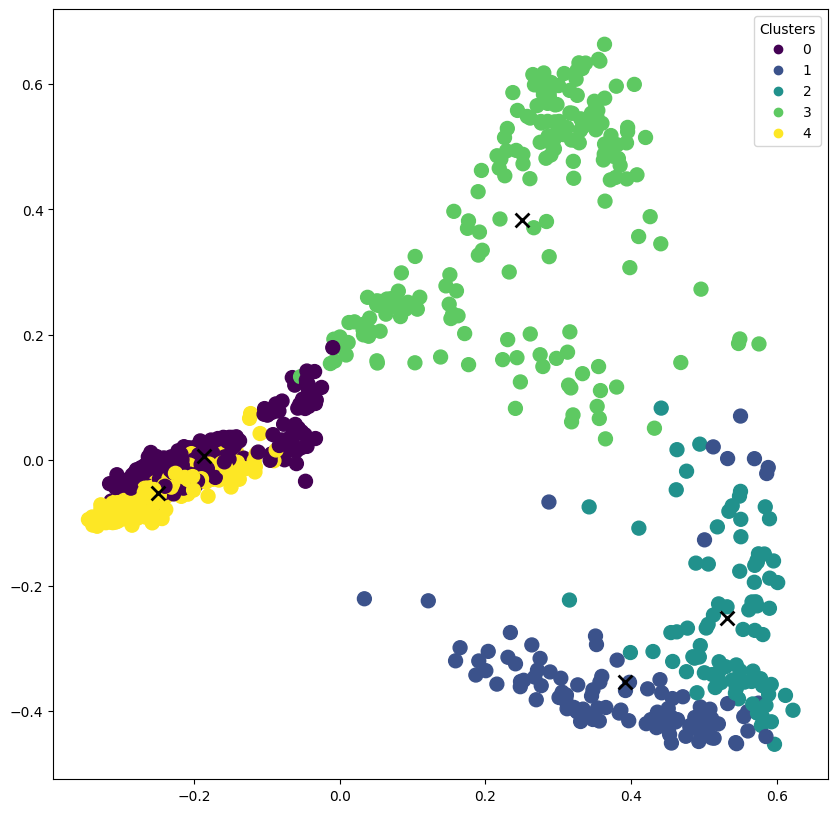

In [43]:
x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10,10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

# Ajouter les centroïdes
centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],  marker = "x", s=100, linewidths = 2, color='black')

# Ajouter la légende
plt.legend(handles=scatter.legend_elements()[0], labels=set(clusters), title="Clusters")

# Enregistrer l'image
os.makedirs(temp_path, exist_ok=True)
plt.savefig(
    os.path.join(temp_path, f"tp3clusters_{N_CLUSTERS}.png"),
    dpi=150,
    bbox_inches="tight",
)
plt.show()